In [53]:
#Impact of Feature Engineering import numpy as np
import matplotlib.pyplot as plt
import random
import pandas as pd
from scipy import stats 
import seaborn as sns
#Define DataSets
ns=1000
#Feature 1 :Age
age=np.random.randint(18,65,ns)
#print(age)
#Feature 2 : Smoker
smoker=np.random.choice([0,1],size=ns,p=[0.4,0.6])
#feature 3: obese
obese=np.random.choice([0,1],size=ns)
#outcome variable : inc. cost
base=1000
bias=np.random.normal(0,100,ns)
ins=base+80*age+1000*smoker+100*obese+bias
df=pd.DataFrame({'Age':age,'Smoker':smoker,'Obese':obese,'Ins_cost':ins})
df

,Age,Smoker,Obese,Ins_cost
0,40,1,0,5279.913731
1,59,0,1,5936.653447
2,55,0,0,5451.455075
3,51,1,1,6193.606364
4,25,1,0,3937.377317
...,...,...,...,...
995,42,0,1,4475.822800
996,43,1,1,5577.047625
997,30,0,0,3501.210966
998,42,0,1,4684.134205


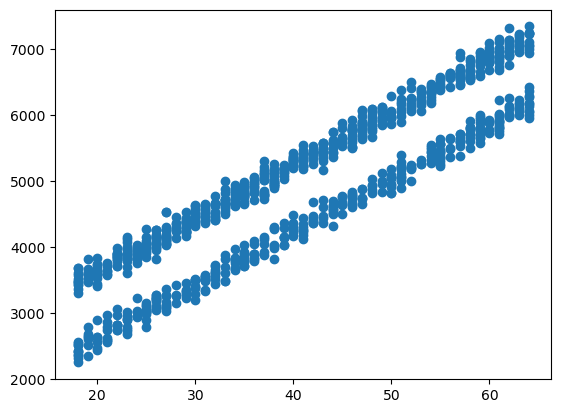

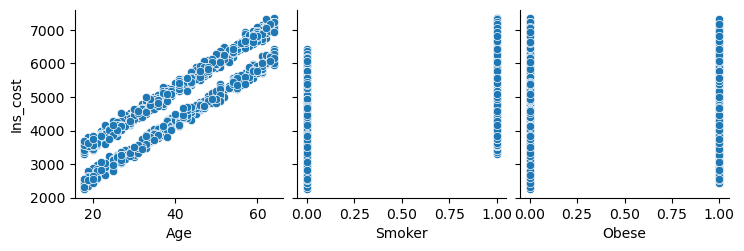

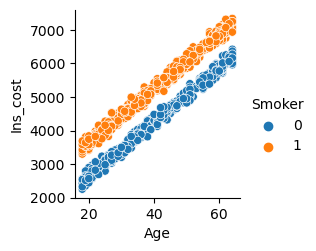

In [54]:
#relation ship between age and insurance cost 
plt.scatter(df.Age,df.Ins_cost)
#relation ship between othe feature and outcome
x =df.drop(columns=['Ins_cost'])
y =df['Ins_cost']
sns.pairplot(df, x_vars=x.columns,y_vars=['Ins_cost'])

#display the impact of smoker on ins. cost
sns.pairplot(df,x_vars=['Age'],y_vars=['Ins_cost'],hue='Smoker')

In [55]:
from sklearn.model_selection import train_test_split
from sklearn import linear_model
lr=linear_model.LinearRegression()
lr.fit(x,y)
ypred=lr.predict(x)
cf=lr.coef_[0]
intc=lr.intercept_
print("Coefficient :",cf.round(2))
print("Intercept:",intc.round(2))

Coefficient : 80.19
Intercept: 986.29


In [56]:
from sklearn import metrics
RSS=(np.sum(y-ypred)**2)
print("RSS:",RSS)
print("MAE",metrics.mean_absolute_error(y,ypred));
print("MSE",metrics.mean_squared_error(y,ypred));
print("RMSE",np.sqrt(metrics.mean_squared_error(y,ypred)));
TSS=np.sum((y-np.mean(y))**2)
print("TSS",TSS)
print("R2 value:",metrics.r2_score(y,ypred))

RSS: 9.11966625339713e-21
MAE 79.52192651819277
MSE 10095.8531800599
RMSE 100.47812289279642
TSS 1407128738.824979
R2 value: 0.9928252100170376


In [57]:
df['Smob']=df.Smoker * df.Obese
print(df)

     Age  Smoker  Obese     Ins_cost  Smob
0     40       1      0  5279.913731     0
1     59       0      1  5936.653447     0
2     55       0      0  5451.455075     0
3     51       1      1  6193.606364     1
4     25       1      0  3937.377317     0
..   ...     ...    ...          ...   ...
995   42       0      1  4475.822800     0
996   43       1      1  5577.047625     1
997   30       0      0  3501.210966     0
998   42       0      1  4684.134205     0
999   59       1      1  6822.507380     1

[1000 rows x 5 columns]


In [61]:
x2=df[['Age','Smob','Smoker','Obese','Ins_cost']]
y2=df['Ins_cost']
lr2=linear_model.LinearRegression()
lr2.fit(x2,y2)
ypred2=lr2.predict(x2)
cf2=lr.coef_[0]
intc2=lr.intercept_
print("Coefficient :",cf2)
print("Intercept:",intc2)
RSS2=(np.sum(y2-ypred2)**2)
print("RSS:",RSS)
print("MAE",metrics.mean_absolute_error(y,ypred));
print("MSE",metrics.mean_squared_error(y,ypred));
print("RMSE",np.sqrt(metrics.mean_squared_error(y,ypred)));
print("\nRSS:",RSS2)
print("MAE",metrics.mean_absolute_error(y2,ypred2));
print("MSE",metrics.mean_squared_error(y2,ypred2));
print("RMSE",np.sqrt(metrics.mean_squared_error(y2,ypred2)));
print("R2:",metrics.r2_score(y2,ypred2))

Coefficient : 80.18834329498833
Intercept: 986.2870345135957
RSS: 9.11966625339713e-21
MAE 79.52192651819277
MSE 10095.8531800599
RMSE 100.47812289279642

RSS: 1.0720260738687239e-19
MAE 6.857590051367879e-13
MSE 7.899574849881414e-25
RMSE 8.887955248470491e-13
R2: 1.0
